# ITNPA4-B34 – Part A: Researchly Expert System (Questions 1 & 2)
Classifying research abstracts (`research_abstracts.json`) into their research-method category (`ai` vs `classical`) using text mining and machine learning.
Source of brief: MATANGA, N.Y. 2026.

In [1]:
import os, re, json, unicodedata, warnings
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
DATA = '../datasets/research_abstracts.json'
FIG = '../docs/figures'; RES = '../results'; DEP = '../deployment'
for d in (FIG, RES, DEP): os.makedirs(d, exist_ok=True)
results = {}
def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG}/{name}', dpi=150, bbox_inches='tight'); plt.close(); display(Image(f'{FIG}/{name}'))

## 1.1 Load the data and denoise the text

In [2]:
df_raw = pd.read_json(DATA)   # column-oriented JSON {column: {index: value}}
print(df_raw.shape); print(df_raw.dtypes); df_raw.head()

(1138, 3)
DOI         str
Abstract    str
Label       str
dtype: object


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


In [3]:
print('Missing values per column:'); print(df_raw.isna().sum())
print('\nDuplicate abstracts:', df_raw.duplicated('Abstract').sum())
print('Duplicate DOIs (non-null):', df_raw['DOI'].dropna().duplicated().sum())
print('\nLabel distribution:'); print(df_raw['Label'].value_counts())
noise = {'LaTeX math ($...$)': r'\$[^$]+\$', 'LaTeX commands': r'\\[a-zA-Z]+', 'HTML tags': r'<[^>]+>',
         'URLs': r'https?://\S+|www\.\S+', 'Copyright notices': r'copyright|©', 'Digits': r'\d',
         'Non-ASCII chars': r'[^\x00-\x7F]'}
noise_counts = {k: int(df_raw['Abstract'].str.contains(p, case=False, regex=True).sum()) for k, p in noise.items()}
results['noise_counts'] = noise_counts
pd.Series(noise_counts, name='abstracts containing noise type')

Missing values per column:
DOI         4
Abstract    0
Label       0
dtype: int64

Duplicate abstracts: 13
Duplicate DOIs (non-null): 0

Label distribution:
Label
classical    900
ai           238
Name: count, dtype: int64


LaTeX math ($...$)     18
LaTeX commands          5
HTML tags               0
URLs                    7
Copyright notices      16
Digits                689
Non-ASCII chars       443
Name: abstracts containing noise type, dtype: int64

The denoising pipeline is written to a reusable module (`deployment/preprocess.py`) so that **exactly the same cleaning** is applied at training time and inside the web app (avoids training/serving skew).

In [4]:
%%writefile ../deployment/preprocess.py
"""Text denoising utilities shared by the notebook and the Streamlit app."""
import re, unicodedata
import spacy

_nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
STOPWORDS = _nlp.Defaults.stop_words | {
    "paper", "study", "article", "result", "results", "author", "authors", "use", "using", "used",
    "propose", "proposed", "show", "find", "finding", "also", "however", "et", "al", "elsevier",
    "wiley", "son", "ltd", "inc", "right", "reserve", "copyright", "journal"}

COPYRIGHT = re.compile(r"(copyright|©|\(c\))[^.]*(\.|$)", re.I)
LATEX_MATH = re.compile(r"\$[^$]*\$")
LATEX_CMD = re.compile(r"\\[a-zA-Z]+(\{[^}]*\})?")
HTML = re.compile(r"<[^>]+>|&[a-z]+;")
URL = re.compile(r"https?://\S+|www\.\S+|doi:\s*\S+", re.I)
EMAIL = re.compile(r"\S+@\S+")
NON_ALPHA = re.compile(r"[^a-z\s]")
SPACES = re.compile(r"\s+")

def denoise(text: str) -> str:
    """Strip markup/boilerplate noise, normalise unicode, lowercase and remove numbers & punctuation."""
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\u2010", "-").replace("\u2011", "-").replace("\u2013", "-").replace("\u2014", " ")
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    for pat in (COPYRIGHT, LATEX_MATH, LATEX_CMD, HTML, URL, EMAIL):
        text = pat.sub(" ", text)
    text = text.lower().replace("-", " ")
    text = NON_ALPHA.sub(" ", text)
    return SPACES.sub(" ", text).strip()

def normalise(text: str) -> str:
    """Lemmatise with spaCy and drop stop words / very short tokens."""
    doc = _nlp(text)
    return " ".join(t.lemma_ for t in doc if t.lemma_ not in STOPWORDS and len(t.lemma_) > 2 and t.is_alpha)

def clean_text(text: str) -> str:
    return normalise(denoise(text))

def clean_many(texts, batch_size=64):
    den = [denoise(t) for t in texts]
    out = []
    for doc in _nlp.pipe(den, batch_size=batch_size):
        out.append(" ".join(t.lemma_ for t in doc if t.lemma_ not in STOPWORDS and len(t.lemma_) > 2 and t.is_alpha))
    return out

Overwriting ../deployment/preprocess.py


In [5]:
import sys; sys.path.insert(0, DEP)
from preprocess import denoise, clean_text, clean_many
df = df_raw.copy()
n0 = len(df)
df = df.dropna(subset=['Abstract', 'Label'])                      # nulls in key columns
df['Abstract'] = df['Abstract'].str.strip()
df = df[df['Abstract'].str.len() > 0]
df = df.drop_duplicates(subset=['Abstract']).reset_index(drop=True)  # duplicate records
df['Label'] = df['Label'].str.strip().str.lower()
df['clean_abstract'] = clean_many(df['Abstract'].tolist())
df = df[df['clean_abstract'].str.split().str.len() >= 5].reset_index(drop=True)  # near-empty after cleaning
print(f'Rows: {n0} raw -> {len(df)} after removing nulls, duplicates and empty texts')
results['rows_raw'] = n0; results['rows_clean'] = len(df)
results['label_counts_clean'] = df['Label'].value_counts().to_dict()
df['raw_words'] = df['Abstract'].str.split().str.len()
df['clean_words'] = df['clean_abstract'].str.split().str.len()
results['median_words_raw'] = float(df['raw_words'].median()); results['median_words_clean'] = float(df['clean_words'].median())
print(df[['raw_words', 'clean_words']].describe().round(1))

Rows: 1138 raw -> 1125 after removing nulls, duplicates and empty texts
       raw_words  clean_words
count     1125.0       1125.0
mean       171.6         94.7
std        103.9         56.2
min         16.0          9.0
25%        116.0         65.0
50%        152.0         86.0
75%        201.0        110.0
max       2075.0       1142.0


In [6]:
ex = df_raw['Abstract'][df_raw['Abstract'].str.contains('Copyright ©', regex=False)].iloc[0]
print('BEFORE:\n', ex[-400:]); print('\nDENOISED:\n', denoise(ex)[-300:]); print('\nLEMMATISED + STOPWORDS REMOVED:\n', clean_text(ex)[-250:])
results['example_before'] = ex[-300:]; results['example_after'] = clean_text(ex)[-200:]

BEFORE:
 ation to a single predictor and a lagged dependent variable. In this paper, I consider using Bayesian model averaging for pseudo out‐of‐sample prediction of US inflation, and find that it generally gives more accurate forecasts than simple equal‐weighted averaging. This superior performance is consistent across subsamples and a number of inflation measures. Copyright © 2008 John Wiley & Sons, Ltd.

DENOISED:
 iable in this paper i consider using bayesian model averaging for pseudo out of sample prediction of us inflation and find that it generally gives more accurate forecasts than simple equal weighted averaging this superior performance is consistent across subsamples and a number of inflation measures

LEMMATISED + STOPWORDS REMOVED:
 relate inflation single predictor lag dependent variable consider bayesian model averaging pseudo sample prediction inflation generally accurate forecast simple equal weighted average superior performance consistent subsample number inflation 

In [7]:
residual = {k: int(df['clean_abstract'].str.contains(p, case=False, regex=True).sum()) for k, p in noise.items()}
print('Abstracts still containing noise after cleaning:', residual); results['residual_noise'] = residual
df.to_csv('../datasets/research_abstracts_clean.csv', index=False)
df[['DOI', 'Label', 'Abstract', 'clean_abstract']].head()

Abstracts still containing noise after cleaning: {'LaTeX math ($...$)': 0, 'LaTeX commands': 0, 'HTML tags': 0, 'URLs': 0, 'Copyright notices': 0, 'Digits': 0, 'Non-ASCII chars': 0}


,DOI,Label,Abstract,clean_abstract
0,10.1155/2021/1071145,ai,Forward-looking forecasting of the inflation r...,forward look forecasting inflation rate help c...
1,10.1007/s43546-022-00384-2,ai,Our study examined the disaggregation of infla...,examine disaggregation inflation component nig...
2,10.1002/for.2667,classical,This paper develops a dynamic factor model tha...,develop dynamic factor model euro area country...
3,10.1007/s42973-021-00091-x,classical,"In this paper, I use a simple SIR Macro model ...",simple sir macro model examine japans soft loc...
4,10.1007/s40258-012-0003-z,classical,BackgroundGame theory is useful for identifyin...,backgroundgame theory useful identify conditio...


## 1.2 Identify columns relevant for feature engineering

In [8]:
profile = pd.DataFrame({'dtype': df_raw.dtypes.astype(str), 'missing': df_raw.isna().sum(),
                        'unique': df_raw.nunique(), 'unique_ratio': (df_raw.nunique() / len(df_raw)).round(3)})
results['column_profile'] = profile.reset_index().rename(columns={'index': 'column'}).to_dict('records')
profile

,dtype,missing,unique,unique_ratio
DOI,str,4,1134,0.996
Abstract,str,0,1125,0.989
Label,str,0,2,0.002


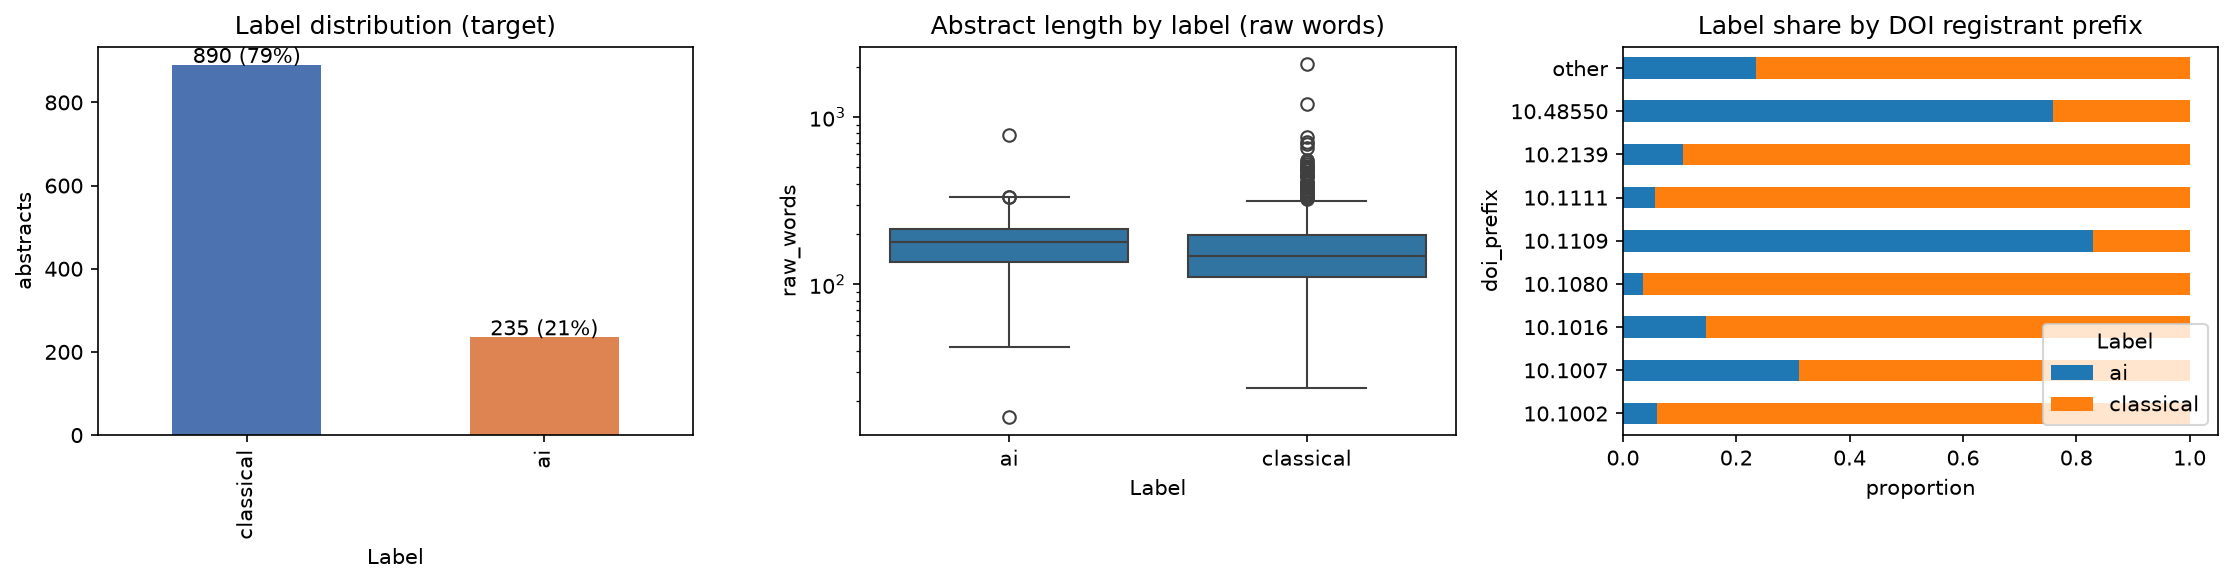

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df['Label'].value_counts().plot.bar(ax=ax[0], color=['#4C72B0', '#DD8452']); ax[0].set_title('Label distribution (target)'); ax[0].set_ylabel('abstracts')
for i, v in enumerate(df['Label'].value_counts()): ax[0].text(i, v + 5, f'{v} ({v/len(df):.0%})', ha='center')
sns.boxplot(data=df, x='Label', y='raw_words', ax=ax[1]); ax[1].set_title('Abstract length by label (raw words)'); ax[1].set_yscale('log')
df['doi_prefix'] = df['DOI'].fillna('missing').str.extract(r'(10\.\d+|ssrn|missing)', expand=False).fillna('other')
top = df['doi_prefix'].value_counts().head(8).index
pd.crosstab(df['doi_prefix'].where(df['doi_prefix'].isin(top), 'other'), df['Label'], normalize='index').plot.barh(stacked=True, ax=ax[2])
ax[2].set_title('Label share by DOI registrant prefix'); ax[2].set_xlabel('proportion')
savefig('q1_2_eda_columns.png')

In [10]:
from sklearn.feature_selection import mutual_info_classif, chi2
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import OrdinalEncoder
y_all = (df['Label'] == 'ai').astype(int)
# Column-level relevance: mutual information of each candidate column (encoded) with the label
cand = pd.DataFrame({'DOI (identifier)': OrdinalEncoder().fit_transform(df[['DOI']].fillna('missing')).ravel(),
                     'DOI prefix (publisher)': OrdinalEncoder().fit_transform(df[['doi_prefix']]).ravel(),
                     'abstract length': df['raw_words']})
mi_cols = dict(zip(cand.columns, mutual_info_classif(cand, y_all, discrete_features=[True, True, False], random_state=RANDOM_STATE)))
tf = TfidfVectorizer(min_df=2); Xt = tf.fit_transform(df['clean_abstract'])
from sklearn.decomposition import TruncatedSVD
lsa = TruncatedSVD(20, random_state=RANDOM_STATE).fit_transform(Xt)
mi_text = mutual_info_classif(lsa, y_all, random_state=RANDOM_STATE)
mi_cols['clean_abstract (TF-IDF/LSA, sum of 20 comps)'] = float(mi_text.sum())
mi_cols = {k: round(float(v), 4) for k, v in mi_cols.items()}; results['mi_columns'] = mi_cols
p_ai = y_all.mean(); H = -(p_ai * np.log(p_ai) + (1 - p_ai) * np.log(1 - p_ai)); results['label_entropy_nats'] = round(float(H), 4)
print('Entropy of Label (upper bound of MI, nats):', round(H, 4), '-> a unique ID trivially reaches this bound by memorising rows')
print('Unique DOIs per row ratio:', round(df['DOI'].nunique() / len(df), 3), '-> DOI is a unique identifier')
pd.Series(mi_cols, name='mutual information with Label').sort_values(ascending=False)

Entropy of Label (upper bound of MI, nats): 0.5125 -> a unique ID trivially reaches this bound by memorising rows
Unique DOIs per row ratio: 0.998 -> DOI is a unique identifier


DOI (identifier)                                0.5125
clean_abstract (TF-IDF/LSA, sum of 20 comps)    0.3515
DOI prefix (publisher)                          0.1924
abstract length                                 0.0296
Name: mutual information with Label, dtype: float64

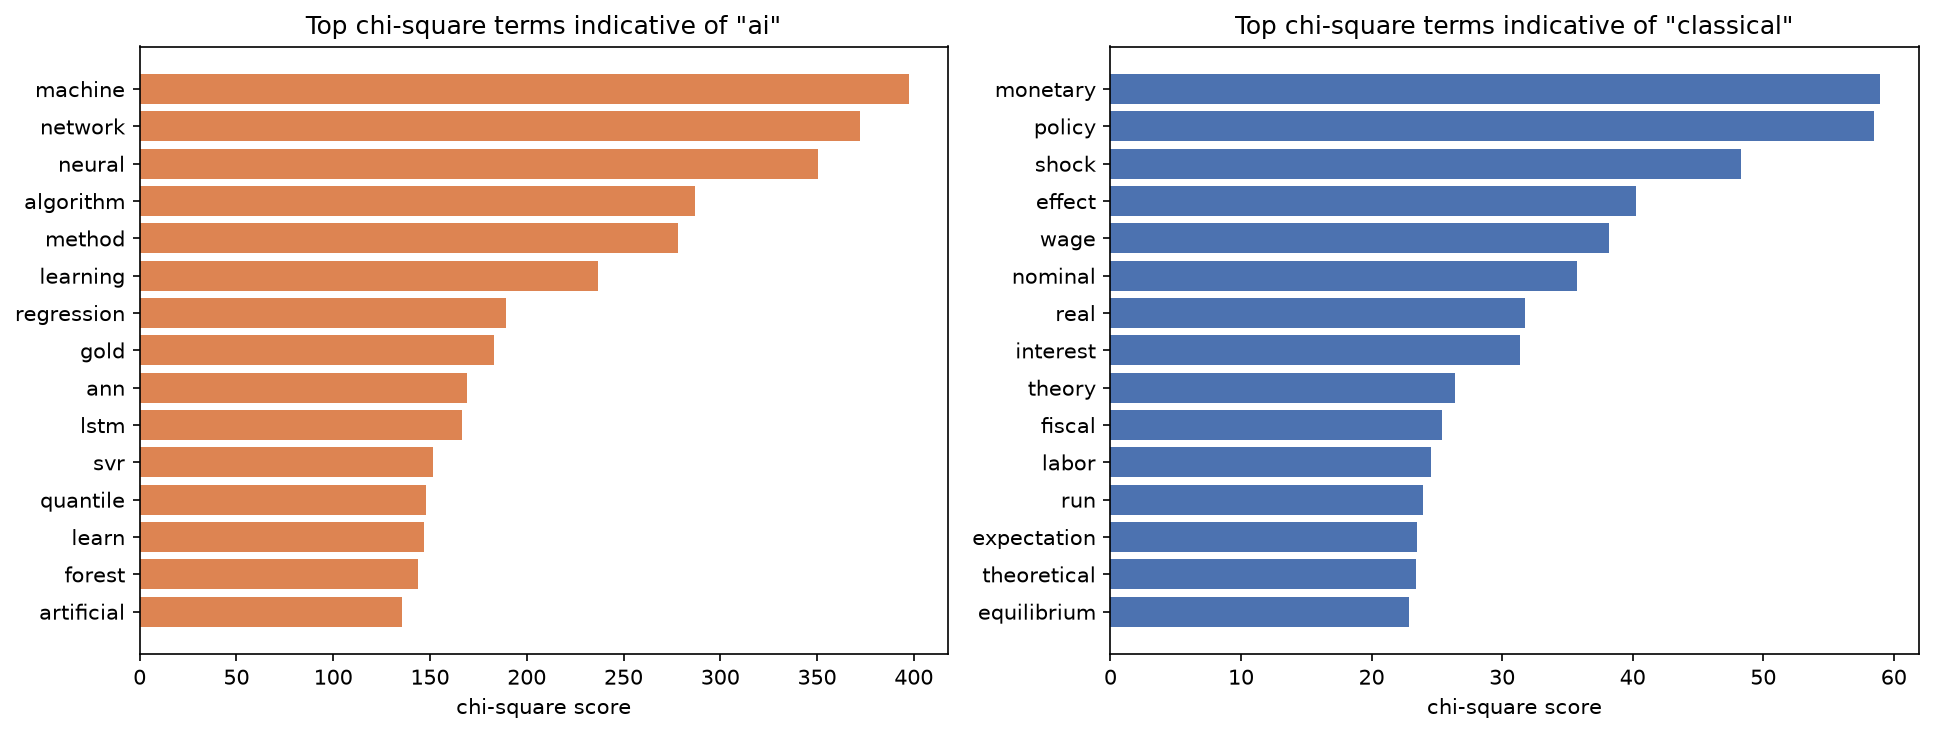

Vocabulary (min_df=3): 2868 | terms significant at p<0.05: 674


,term,chi2,p,class
1527,machine,397.659574,1.779998e-88,ai
1705,network,372.382486,5.668362e-83,ai
1706,neural,350.276464,3.689231e-78,ai
88,algorithm,287.123369,2.105517e-64,ai
1600,method,277.997960,2.050600e-62,ai
1465,learning,237.059727,1.721205e-53,ai
2151,regression,189.448199,4.195447e-43,ai
1140,gold,183.031629,1.055656e-41,ai
114,ann,169.260103,1.073419e-38,ai
1525,lstm,166.638298,4.012710e-38,ai


In [11]:
cv = CountVectorizer(min_df=3); Xc = cv.fit_transform(df['clean_abstract'])
chi, p = chi2(Xc, y_all); vocab = np.array(cv.get_feature_names_out())
freq_ai = np.asarray(Xc[y_all.values == 1].mean(0)).ravel(); freq_cl = np.asarray(Xc[y_all.values == 0].mean(0)).ravel()
chi_df = pd.DataFrame({'term': vocab, 'chi2': chi, 'p': p, 'class': np.where(freq_ai > freq_cl, 'ai', 'classical')}).sort_values('chi2', ascending=False)
results['vocab_size_min_df3'] = int(len(vocab)); results['sig_terms_p_lt_0_05'] = int((chi_df.p < 0.05).sum())
results['top_chi2_ai'] = chi_df[chi_df['class'] == 'ai'].head(10)[['term', 'chi2']].round(1).values.tolist()
results['top_chi2_classical'] = chi_df[chi_df['class'] == 'classical'].head(10)[['term', 'chi2']].round(1).values.tolist()
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, c, col in zip(ax, ['ai', 'classical'], ['#DD8452', '#4C72B0']):
    t = chi_df[chi_df['class'] == c].head(15)[::-1]; a.barh(t['term'], t['chi2'], color=col); a.set_title(f'Top chi-square terms indicative of "{c}"'); a.set_xlabel('chi-square score')
savefig('q1_2_chi2_terms.png')
print('Vocabulary (min_df=3):', len(vocab), '| terms significant at p<0.05:', (chi_df.p < 0.05).sum())
chi_df.head(15)

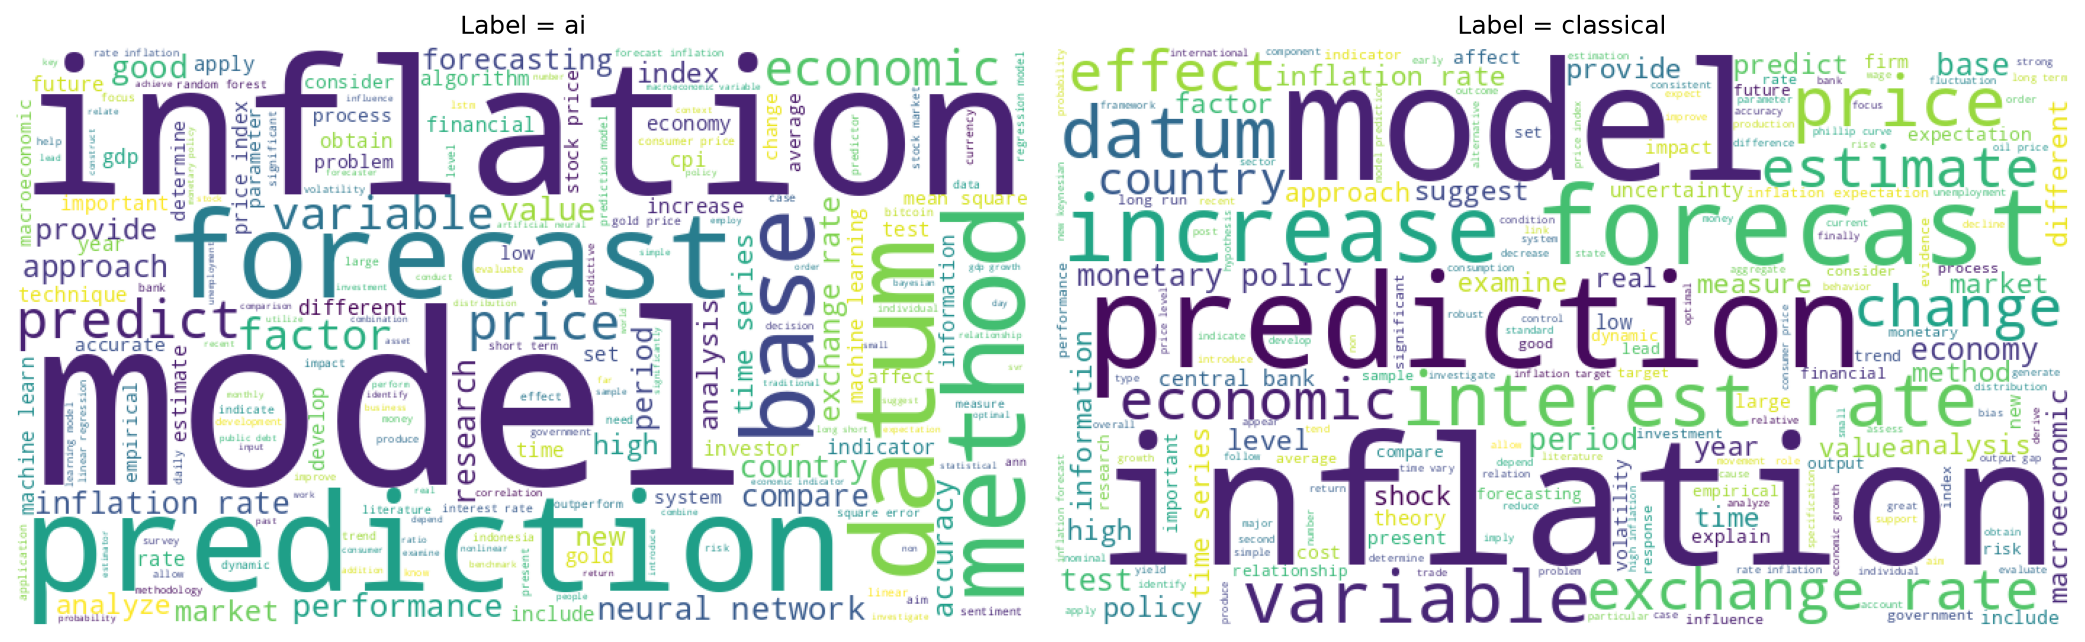

In [12]:
from wordcloud import WordCloud
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, c in zip(ax, ['ai', 'classical']):
    wc = WordCloud(width=700, height=400, background_color='white', random_state=RANDOM_STATE).generate(' '.join(df.loc[df.Label == c, 'clean_abstract']))
    a.imshow(wc); a.axis('off'); a.set_title(f'Label = {c}')
savefig('q1_2_wordclouds_by_label.png')

**Decision:** `clean_abstract` (derived from `Abstract`) is the feature column, `Label` is the target. `DOI` is a unique identifier (near 1.0 unique ratio, 4 missing) and is excluded – using it or its publisher prefix would leak bibliographic metadata rather than learn semantic content, and it is not available when a researcher pastes a new abstract.

## 1.3 Baseline model

In [13]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
X = df['clean_abstract']; y = df['Label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape[0], dict(y_train.value_counts()), '| Test:', X_test.shape[0], dict(y_test.value_counts()))
results['split'] = {'train': int(len(X_train)), 'test': int(len(X_test))}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro', 'f1_ai': 'f1', 'roc_auc': 'roc_auc'}
from sklearn.metrics import make_scorer
SCORING['f1_ai'] = make_scorer(f1_score, pos_label='ai')

def evaluate(model, name):
    model.fit(X_train, y_train)
    out = {'model': name}
    for split, Xs, ys in (('train', X_train, y_train), ('test', X_test, y_test)):
        pr = model.predict(Xs)
        out[f'{split}_accuracy'] = accuracy_score(ys, pr); out[f'{split}_f1_macro'] = f1_score(ys, pr, average='macro')
        out[f'{split}_f1_ai'] = f1_score(ys, pr, pos_label='ai', zero_division=0)
        out[f'{split}_recall_ai'] = recall_score(ys, pr, pos_label='ai', zero_division=0)
        out[f'{split}_precision_ai'] = precision_score(ys, pr, pos_label='ai', zero_division=0)
        if hasattr(model, 'predict_proba'):
            s = model.predict_proba(Xs)[:, list(model.classes_).index('ai')]
        else:  # decision_function is positive for classes_[1]; flip sign so higher = more 'ai'
            s = model.decision_function(Xs) * (1 if model.classes_[1] == 'ai' else -1)
        out[f'{split}_roc_auc'] = roc_auc_score((ys == 'ai').astype(int), s)
    cvr = cross_validate(model, X_train, y_train, cv=skf, scoring=SCORING, n_jobs=-1)
    out['cv_f1_macro_mean'] = cvr['test_f1_macro'].mean(); out['cv_f1_macro_std'] = cvr['test_f1_macro'].std()
    out['cv_accuracy_mean'] = cvr['test_accuracy'].mean()
    return {k: (round(float(v), 4) if not isinstance(v, str) else v) for k, v in out.items()}

Train: 900 {'classical': np.int64(712), 'ai': np.int64(188)} | Test: 225 {'classical': np.int64(178), 'ai': np.int64(47)}


In [14]:
dummy = evaluate(DummyClassifier(strategy='most_frequent'), 'Dummy (majority class)')
baseline = Pipeline([('tfidf', TfidfVectorizer()), ('clf', MultinomialNB())])
base_res = evaluate(baseline, 'Baseline: TF-IDF + Multinomial NB')
results['dummy'] = dummy; results['baseline'] = base_res
pd.DataFrame([dummy, base_res]).set_index('model').T

model,Dummy (majority class),Baseline: TF-IDF + Multinomial NB
train_accuracy,0.7911,0.8189
train_f1_macro,0.4417,0.5660
train_f1_ai,0.0000,0.2347
train_recall_ai,0.0000,0.1330
train_precision_ai,0.0000,1.0000
train_roc_auc,0.5000,0.9639
test_accuracy,0.7911,0.8089
test_f1_macro,0.4417,0.5245
test_f1_ai,0.0000,0.1569
test_recall_ai,0.0000,0.0851


Classification report – TRAIN (learning)
              precision    recall  f1-score   support

          ai      1.000     0.133     0.235       188
   classical      0.814     1.000     0.897       712

    accuracy                          0.819       900
   macro avg      0.907     0.566     0.566       900
weighted avg      0.853     0.819     0.759       900

Classification report – TEST (generalisation)
              precision    recall  f1-score   support

          ai      1.000     0.085     0.157        47
   classical      0.805     1.000     0.892       178

    accuracy                          0.809       225
   macro avg      0.903     0.543     0.525       225
weighted avg      0.846     0.809     0.739       225



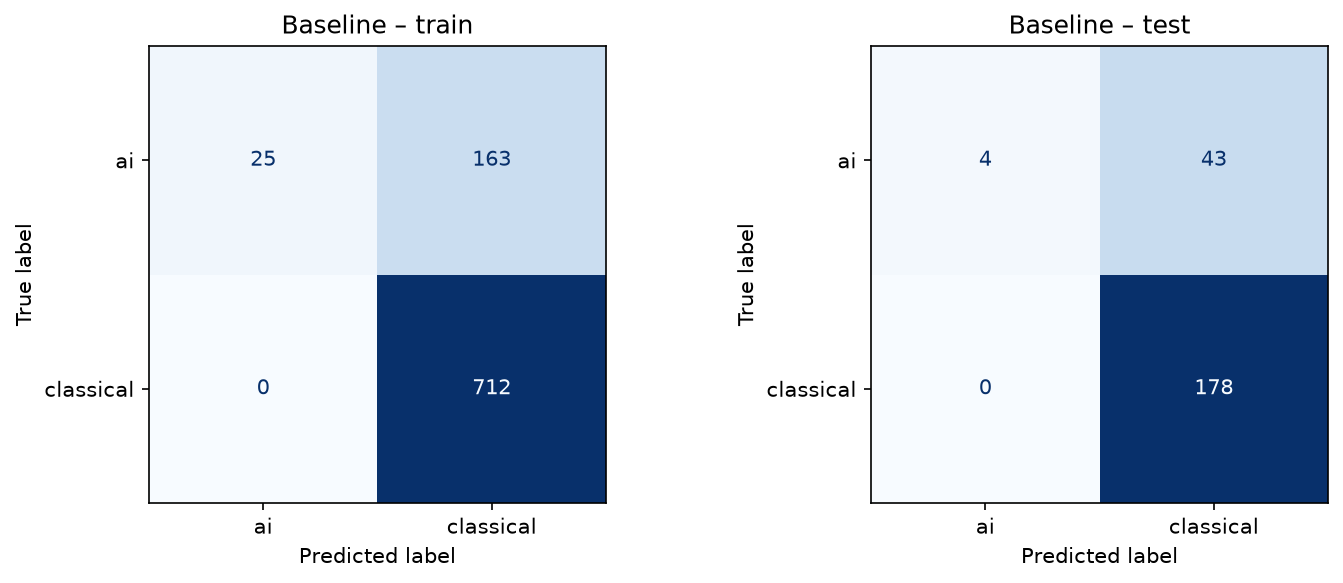

In [15]:
print('Classification report – TRAIN (learning)'); print(classification_report(y_train, baseline.predict(X_train), digits=3))
print('Classification report – TEST (generalisation)'); rep = classification_report(y_test, baseline.predict(X_test), digits=3); print(rep)
results['baseline_report_test'] = classification_report(y_test, baseline.predict(X_test), output_dict=True)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(baseline, X_train, y_train, ax=ax[0], cmap='Blues', colorbar=False); ax[0].set_title('Baseline – train')
ConfusionMatrixDisplay.from_estimator(baseline, X_test, y_test, ax=ax[1], cmap='Blues', colorbar=False); ax[1].set_title('Baseline – test')
results['baseline_cm_test'] = confusion_matrix(y_test, baseline.predict(X_test), labels=['ai', 'classical']).tolist()
savefig('q1_3_baseline_confusion.png')

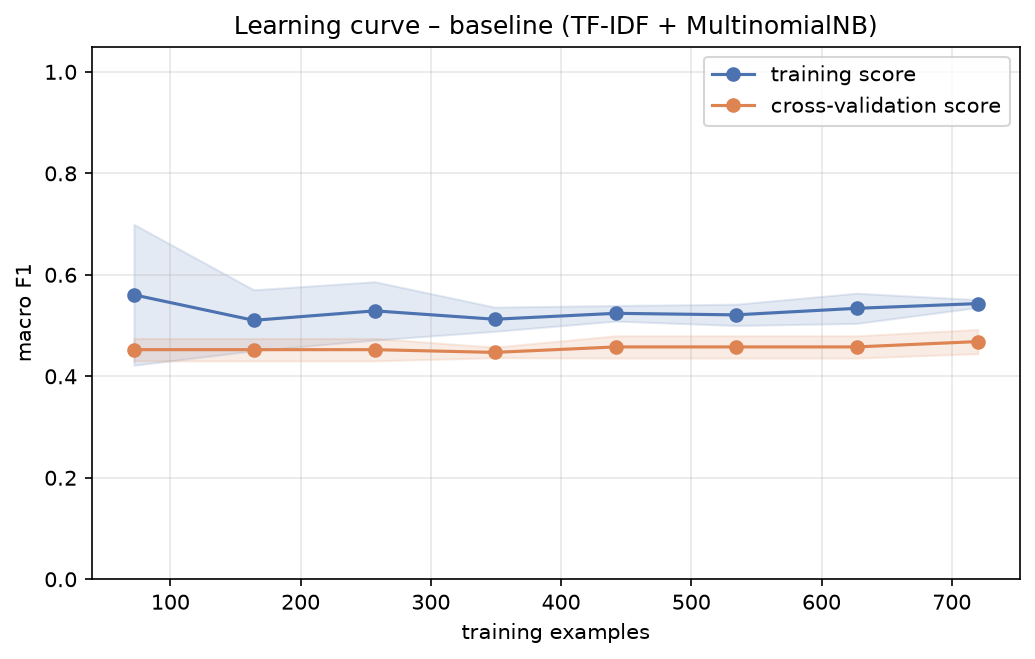

{'sizes': [72, 164, 257, 349, 442, 534, 627, 720],
 'train': [0.5606, 0.5103, 0.529, 0.5125, 0.5241, 0.5211, 0.534, 0.5433],
 'cv': [0.4525, 0.4525, 0.4525, 0.4471, 0.4579, 0.4579, 0.4579, 0.4684]}

In [16]:
def plot_learning_curve(model, title, fname):
    sizes, tr, va = learning_curve(model, X_train, y_train, cv=skf, scoring='f1_macro', train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, shuffle=True, random_state=RANDOM_STATE)
    plt.figure(figsize=(7, 4.5))
    for s, lab, c in ((tr, 'training score', '#4C72B0'), (va, 'cross-validation score', '#DD8452')):
        plt.plot(sizes, s.mean(1), 'o-', color=c, label=lab); plt.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.15, color=c)
    plt.xlabel('training examples'); plt.ylabel('macro F1'); plt.ylim(0, 1.05); plt.title(title); plt.legend(); plt.grid(alpha=0.3)
    savefig(fname)
    return {'sizes': sizes.tolist(), 'train': tr.mean(1).round(4).tolist(), 'cv': va.mean(1).round(4).tolist()}
results['baseline_learning_curve'] = plot_learning_curve(baseline, 'Learning curve – baseline (TF-IDF + MultinomialNB)', 'q1_3_baseline_learning_curve.png')
results['baseline_learning_curve']

## 2.1 Four (plus) machine learning models

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
vec = lambda: TfidfVectorizer(sublinear_tf=True, min_df=2)
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Linear SVM': LinearSVC(class_weight='balanced'),
    'Complement NB': ComplementNB(),
    'Random Forest': RandomForestClassifier(n_estimators=400, class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
}
rows = [base_res]
fitted = {}
for name, clf in models.items():
    pipe = Pipeline([('tfidf', vec()), ('clf', clf)])
    rows.append(evaluate(pipe, name)); fitted[name] = pipe
comp = pd.DataFrame(rows).set_index('model')
results['model_comparison'] = comp.reset_index().to_dict('records')
comp[['train_f1_macro', 'test_accuracy', 'test_f1_macro', 'test_f1_ai', 'test_recall_ai', 'test_roc_auc', 'cv_f1_macro_mean', 'cv_f1_macro_std']]

,train_f1_macro,test_accuracy,test_f1_macro,test_f1_ai,test_recall_ai,test_roc_auc,cv_f1_macro_mean,cv_f1_macro_std
model,,,,,,,,
Baseline: TF-IDF + Multinomial NB,0.5660,0.8089,0.5245,0.1569,0.0851,0.9166,0.4684,0.0239
Logistic Regression,0.9670,0.8933,0.8435,0.7551,0.7872,0.9399,0.8305,0.0183
Linear SVM,0.9983,0.9200,0.8729,0.7955,0.7447,0.9448,0.8496,0.0291
Complement NB,0.9089,0.9022,0.8221,0.7027,0.5532,0.9306,0.7978,0.0472
Random Forest,1.0000,0.9200,0.8575,0.7632,0.6170,0.9404,0.7912,0.0246
Gradient Boosting,0.9722,0.9111,0.8480,0.7500,0.6383,0.8888,0.8443,0.0199


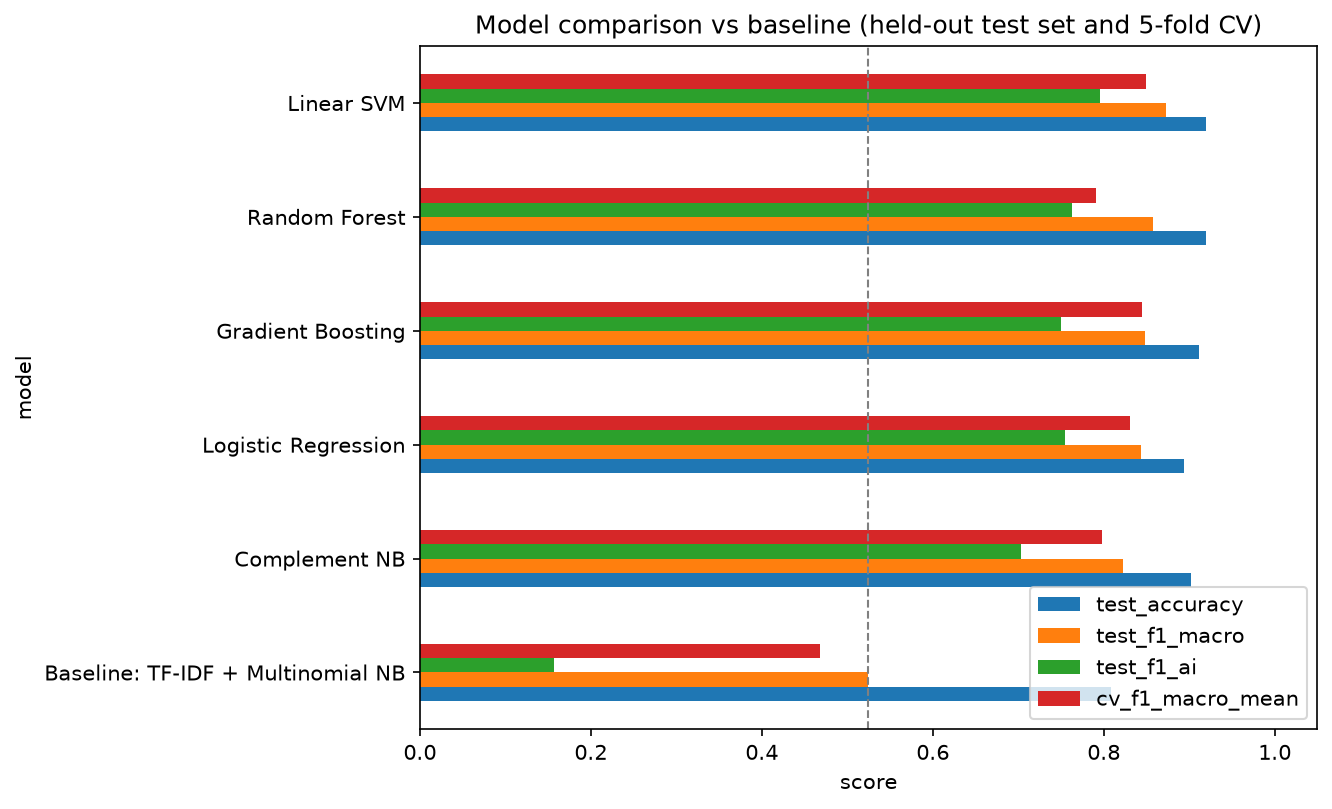

Best untuned model by test macro-F1: Linear SVM


In [18]:
plot = comp[['test_accuracy', 'test_f1_macro', 'test_f1_ai', 'cv_f1_macro_mean']].sort_values('test_f1_macro')
ax = plot.plot.barh(figsize=(9, 5.5)); ax.set_xlim(0, 1.05); ax.set_title('Model comparison vs baseline (held-out test set and 5-fold CV)'); ax.set_xlabel('score')
ax.axvline(base_res['test_f1_macro'], ls='--', c='grey', lw=1); ax.legend(loc='lower right')
savefig('q2_1_model_comparison.png')
best_name = comp.drop(index=base_res['model'])['test_f1_macro'].idxmax(); results['best_untuned'] = best_name
print('Best untuned model by test macro-F1:', best_name)

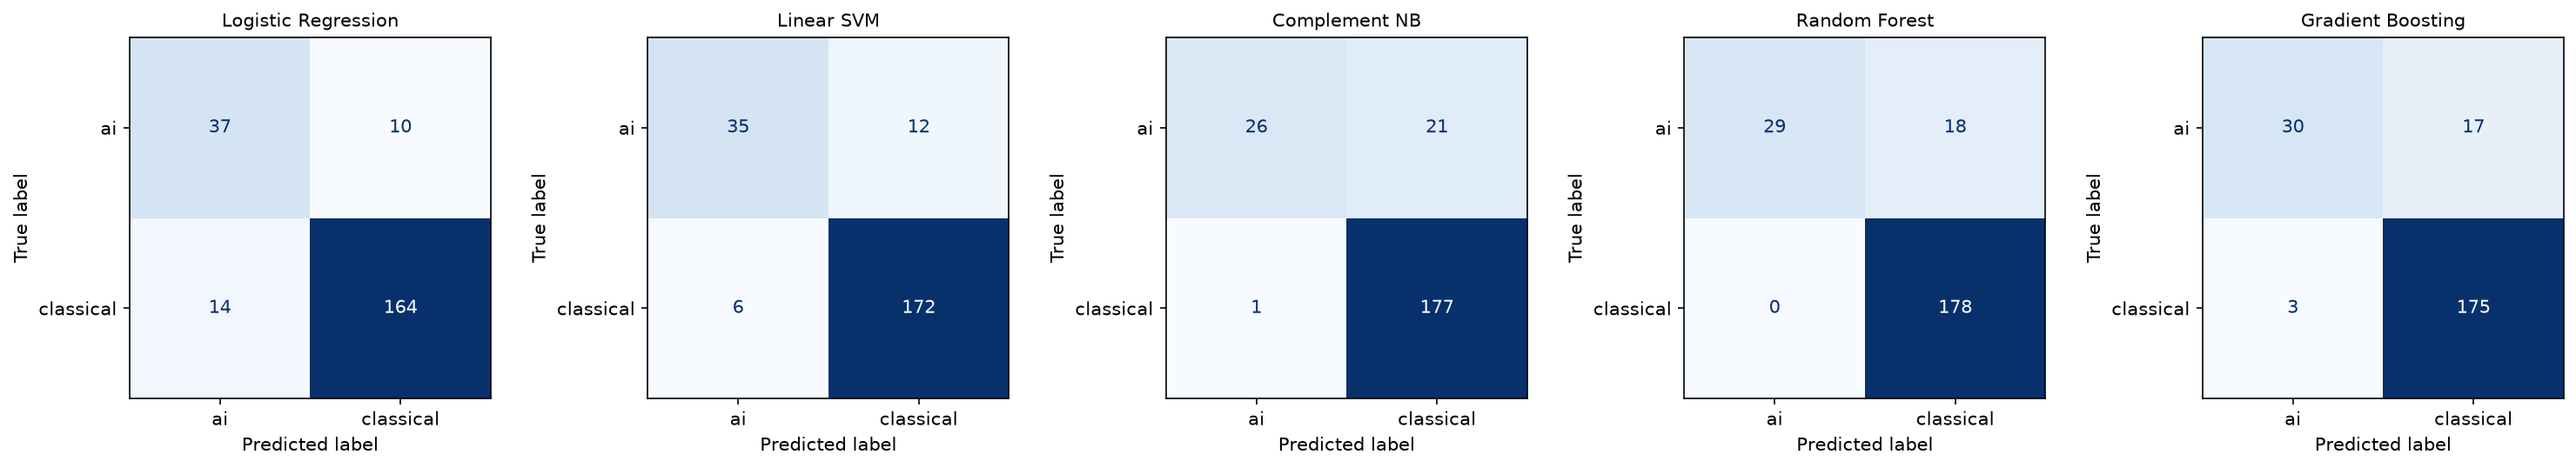

In [19]:
fig, axes = plt.subplots(1, len(fitted), figsize=(4 * len(fitted), 3.6))
for a, (n, m) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=a, cmap='Blues', colorbar=False); a.set_title(n, fontsize=10)
savefig('q2_1_confusion_matrices.png')

## 2.2 Performance enhancement: hyperparameter optimisation with GridSearchCV (incl. n-gram feature engineering)

In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import CalibratedClassifierCV
grids = {
  'Logistic Regression': (LogisticRegression(max_iter=3000, class_weight='balanced'),
       {'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)], 'tfidf__min_df': [1, 2, 3], 'tfidf__sublinear_tf': [True, False], 'clf__C': [0.5, 1, 5, 10, 30]}),
  'Linear SVM': (LinearSVC(class_weight='balanced'),
       {'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)], 'tfidf__min_df': [1, 2, 3], 'tfidf__sublinear_tf': [True, False], 'clf__C': [0.05, 0.1, 0.5, 1, 5]}),
}
tuned = {}; tuned_rows = []
for name, (clf, grid) in grids.items():
    gs = GridSearchCV(Pipeline([('tfidf', TfidfVectorizer()), ('clf', clf)]), grid, scoring='f1_macro', cv=skf, n_jobs=-1)
    gs.fit(X_train, y_train)
    print(name, 'best CV macro-F1 =', round(gs.best_score_, 4), gs.best_params_)
    tuned[name] = gs
    r = evaluate(gs.best_estimator_, f'{name} (tuned)'); r['best_params'] = str(gs.best_params_); tuned_rows.append(r)
results['tuned'] = tuned_rows
pd.DataFrame(tuned_rows).set_index('model')[['train_f1_macro', 'test_accuracy', 'test_f1_macro', 'test_f1_ai', 'test_roc_auc', 'cv_f1_macro_mean', 'best_params']]

Logistic Regression best CV macro-F1 = 0.8584 {'clf__C': 10, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}


Linear SVM best CV macro-F1 = 0.8556 {'clf__C': 1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}


,train_f1_macro,test_accuracy,test_f1_macro,test_f1_ai,test_roc_auc,cv_f1_macro_mean,best_params
model,,,,,,,
Logistic Regression (tuned),0.9983,0.9156,0.8691,0.7912,0.9463,0.8584,"{'clf__C': 10, 'tfidf__min_df': 1, 'tfidf__ngr..."
Linear SVM (tuned),0.9983,0.9244,0.8809,0.8090,0.9453,0.8556,"{'clf__C': 1, 'tfidf__min_df': 1, 'tfidf__ngra..."


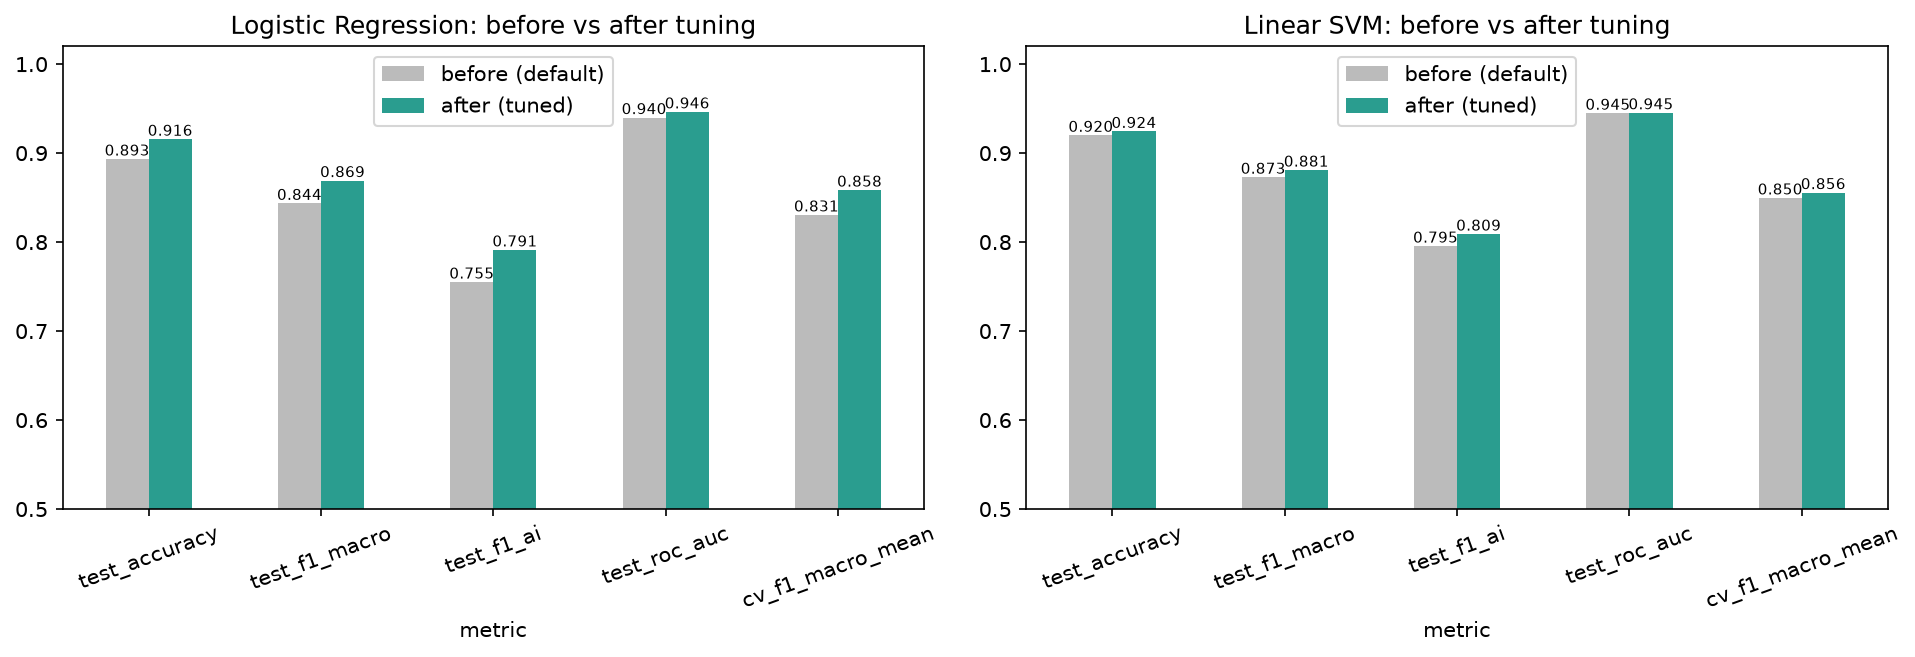

,model,metric,before (default),after (tuned),change
0,Logistic Regression,test_accuracy,0.8933,0.9156,0.0223
1,Logistic Regression,test_f1_macro,0.8435,0.8691,0.0256
2,Logistic Regression,test_f1_ai,0.7551,0.7912,0.0361
3,Logistic Regression,test_roc_auc,0.9399,0.9463,0.0064
4,Logistic Regression,cv_f1_macro_mean,0.8305,0.8584,0.0279
5,Linear SVM,test_accuracy,0.9200,0.9244,0.0044
6,Linear SVM,test_f1_macro,0.8729,0.8809,0.0080
7,Linear SVM,test_f1_ai,0.7955,0.8090,0.0135
8,Linear SVM,test_roc_auc,0.9448,0.9453,0.0005
9,Linear SVM,cv_f1_macro_mean,0.8496,0.8556,0.0060


In [21]:
before_after = []
for name in grids:
    b = comp.loc[name]; a = pd.DataFrame(tuned_rows).set_index('model').loc[f'{name} (tuned)']
    for m in ['test_accuracy', 'test_f1_macro', 'test_f1_ai', 'test_roc_auc', 'cv_f1_macro_mean']:
        before_after.append({'model': name, 'metric': m, 'before (default)': b[m], 'after (tuned)': a[m], 'change': round(a[m] - b[m], 4)})
ba = pd.DataFrame(before_after); results['before_after'] = ba.to_dict('records')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for a, name in zip(axes, grids):
    t = ba[ba.model == name].set_index('metric')[['before (default)', 'after (tuned)']]
    t.plot.bar(ax=a, rot=20, color=['#bbbbbb', '#2a9d8f']); a.set_ylim(0.5, 1.02); a.set_title(f'{name}: before vs after tuning')
    for c in a.containers: a.bar_label(c, fmt='%.3f', fontsize=7)
savefig('q2_2_before_after_tuning.png')
ba

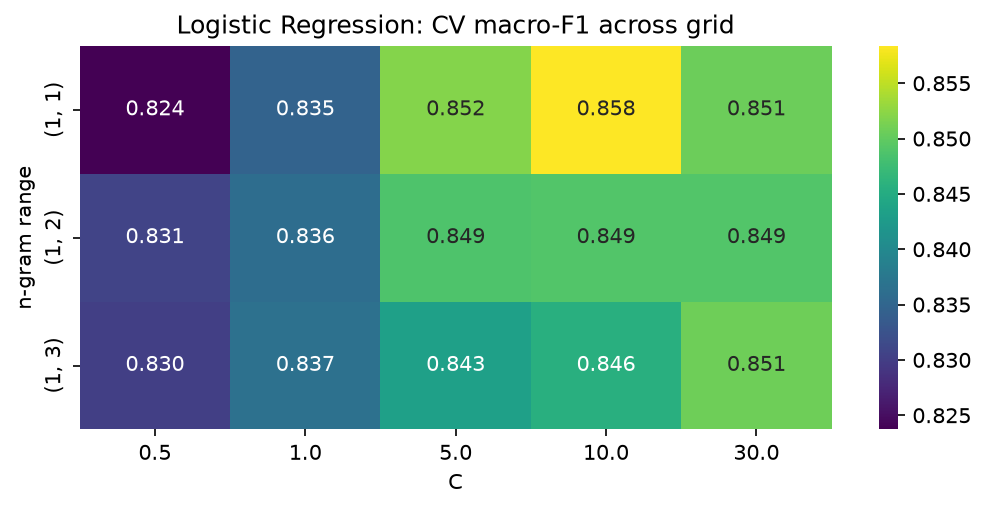

In [22]:
# heat-map of the grid for the best family: macro-F1 by n-gram range and C (best min_df / sublinear setting)
best_family = max(tuned, key=lambda n: tuned[n].best_score_)
cvres = pd.DataFrame(tuned[best_family].cv_results_)
bp = tuned[best_family].best_params_
sub = cvres[(cvres.param_tfidf__min_df == bp['tfidf__min_df']) & (cvres.param_tfidf__sublinear_tf == bp['tfidf__sublinear_tf'])]
hm = sub.pivot_table(index=sub.param_tfidf__ngram_range.astype(str), columns='param_clf__C', values='mean_test_score')
plt.figure(figsize=(7, 3.5)); sns.heatmap(hm, annot=True, fmt='.3f', cmap='viridis'); plt.title(f'{best_family}: CV macro-F1 across grid'); plt.ylabel('n-gram range'); plt.xlabel('C')
savefig('q2_2_grid_heatmap.png')
results['best_family'] = best_family

              precision    recall  f1-score   support

          ai      0.818     0.766     0.791        47
   classical      0.939     0.955     0.947       178

    accuracy                          0.916       225
   macro avg      0.879     0.861     0.869       225
weighted avg      0.914     0.916     0.915       225



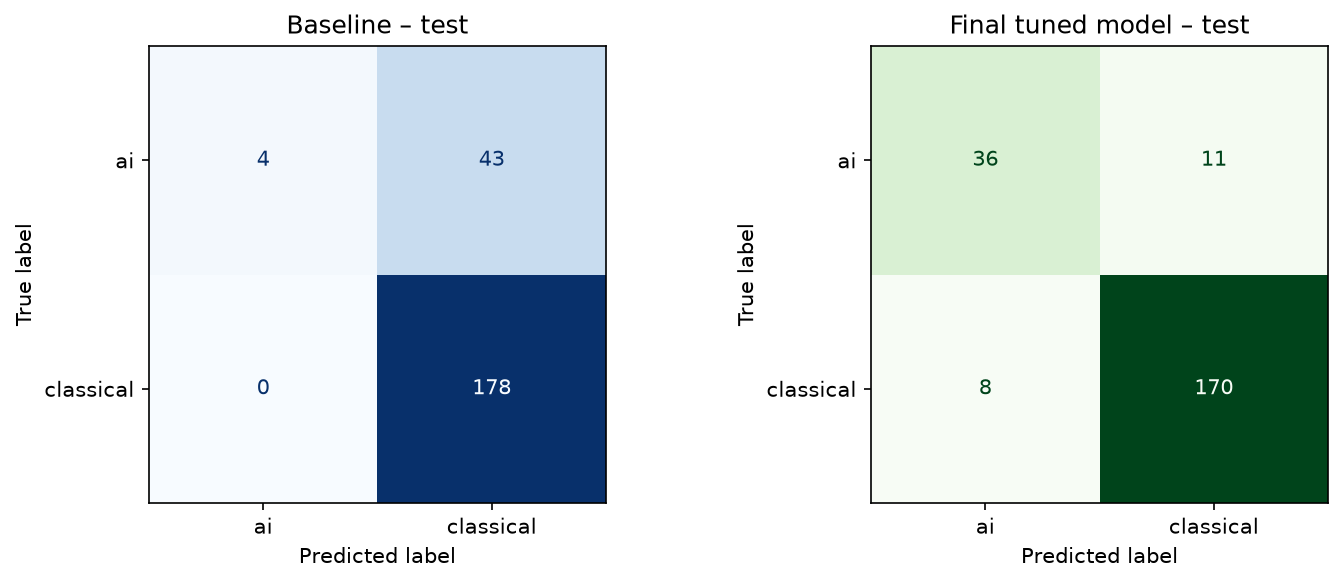

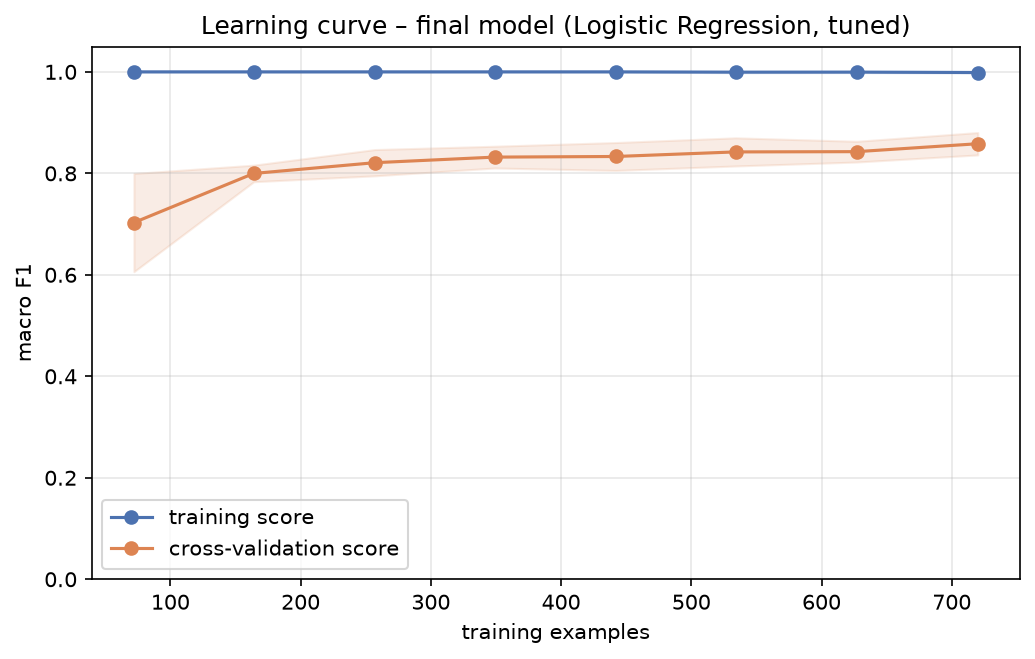

model,Baseline: TF-IDF + Multinomial NB,"FINAL: Logistic Regression (tuned, deployed)"
train_accuracy,0.8189,0.9989
train_f1_macro,0.5660,0.9983
train_f1_ai,0.2347,0.9973
train_recall_ai,0.1330,1.0000
train_precision_ai,1.0000,0.9947
train_roc_auc,0.9639,1.0000
test_accuracy,0.8089,0.9156
test_f1_macro,0.5245,0.8691
test_f1_ai,0.1569,0.7912
test_recall_ai,0.0851,0.7660


In [23]:
# Final model: choose by CV macro-F1 (train data only) to avoid tuning on the test set
final_name = best_family
final = tuned[final_name].best_estimator_
if not hasattr(final, 'predict_proba'):
    # Wrap the SVM in Platt scaling so the web app can show calibrated class probabilities
    final = Pipeline([('tfidf', final.named_steps['tfidf']), ('clf', CalibratedClassifierCV(final.named_steps['clf'], cv=5, method='sigmoid'))])
final_res = evaluate(final, f'FINAL: {final_name} (tuned, deployed)'); results['final'] = final_res
print(classification_report(y_test, final.predict(X_test), digits=3))
results['final_report_test'] = classification_report(y_test, final.predict(X_test), output_dict=True)
results['final_cm_test'] = confusion_matrix(y_test, final.predict(X_test), labels=['ai', 'classical']).tolist()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(baseline, X_test, y_test, ax=ax[0], cmap='Blues', colorbar=False); ax[0].set_title('Baseline – test')
ConfusionMatrixDisplay.from_estimator(final, X_test, y_test, ax=ax[1], cmap='Greens', colorbar=False); ax[1].set_title('Final tuned model – test')
savefig('q2_2_final_vs_baseline_confusion.png')
results['final_learning_curve'] = plot_learning_curve(final, f'Learning curve – final model ({final_name}, tuned)', 'q2_2_final_learning_curve.png')
pd.DataFrame([base_res, final_res]).set_index('model').T

## 2.3 Save the best configuration for the web interface

In [24]:
import joblib, sklearn
final.fit(X, y)   # refit on all cleaned data for deployment
joblib.dump(final, f'{DEP}/model.joblib')
meta = {'model': final_name + ' (GridSearchCV-tuned)', 'params': str(tuned[final_name].best_params_), 'classes': list(final.classes_),
        'test_metrics': {k: final_res[k] for k in ['test_accuracy', 'test_f1_macro', 'test_f1_ai', 'test_roc_auc']},
        'cv_f1_macro': final_res['cv_f1_macro_mean'], 'trained_on_rows': int(len(X)), 'sklearn_version': sklearn.__version__}
json.dump(meta, open(f'{DEP}/model_meta.json', 'w'), indent=2)
from preprocess import clean_text
m = joblib.load(f'{DEP}/model.joblib')
for t in ['We train a long short-term memory neural network and random forest to forecast inflation and compare with machine learning benchmarks.',
          'We estimate a vector autoregression and Phillips curve model to forecast inflation using Bayesian econometric methods.']:
    print(m.predict([clean_text(t)])[0], dict(zip(m.classes_, m.predict_proba([clean_text(t)])[0].round(3))))
meta

ai {'ai': np.float64(1.0), 'classical': np.float64(0.0)}
classical {'ai': np.float64(0.081), 'classical': np.float64(0.919)}


{'model': 'Logistic Regression (GridSearchCV-tuned)',
 'params': "{'clf__C': 10, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}",
 'classes': ['ai', 'classical'],
 'test_metrics': {'test_accuracy': 0.9156,
  'test_f1_macro': 0.8691,
  'test_f1_ai': 0.7912,
  'test_roc_auc': 0.9463},
 'cv_f1_macro': 0.8584,
 'trained_on_rows': 1125,
 'sklearn_version': '1.9.1'}

### Web interface (Streamlit)
The app in `deployment/app.py` loads `model.joblib`, applies the same `clean_text` denoising and shows the predicted category with class probabilities. Run it with `streamlit run deployment/app.py`. Screenshots captured from the running app (headless Chromium via Playwright):

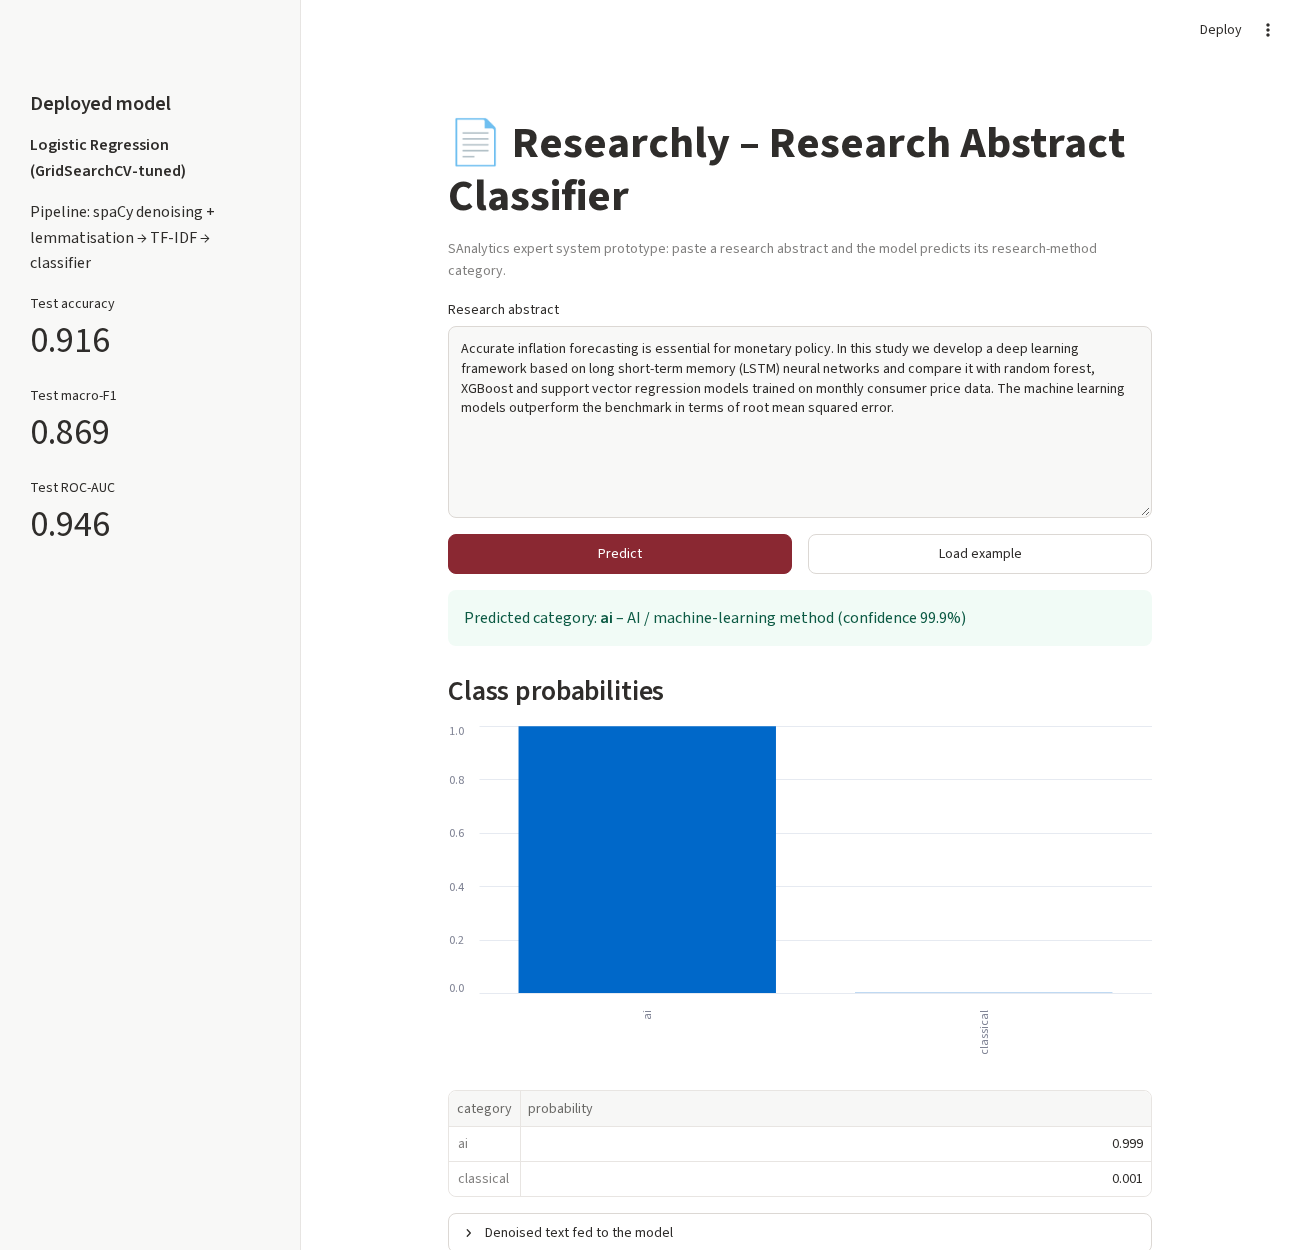

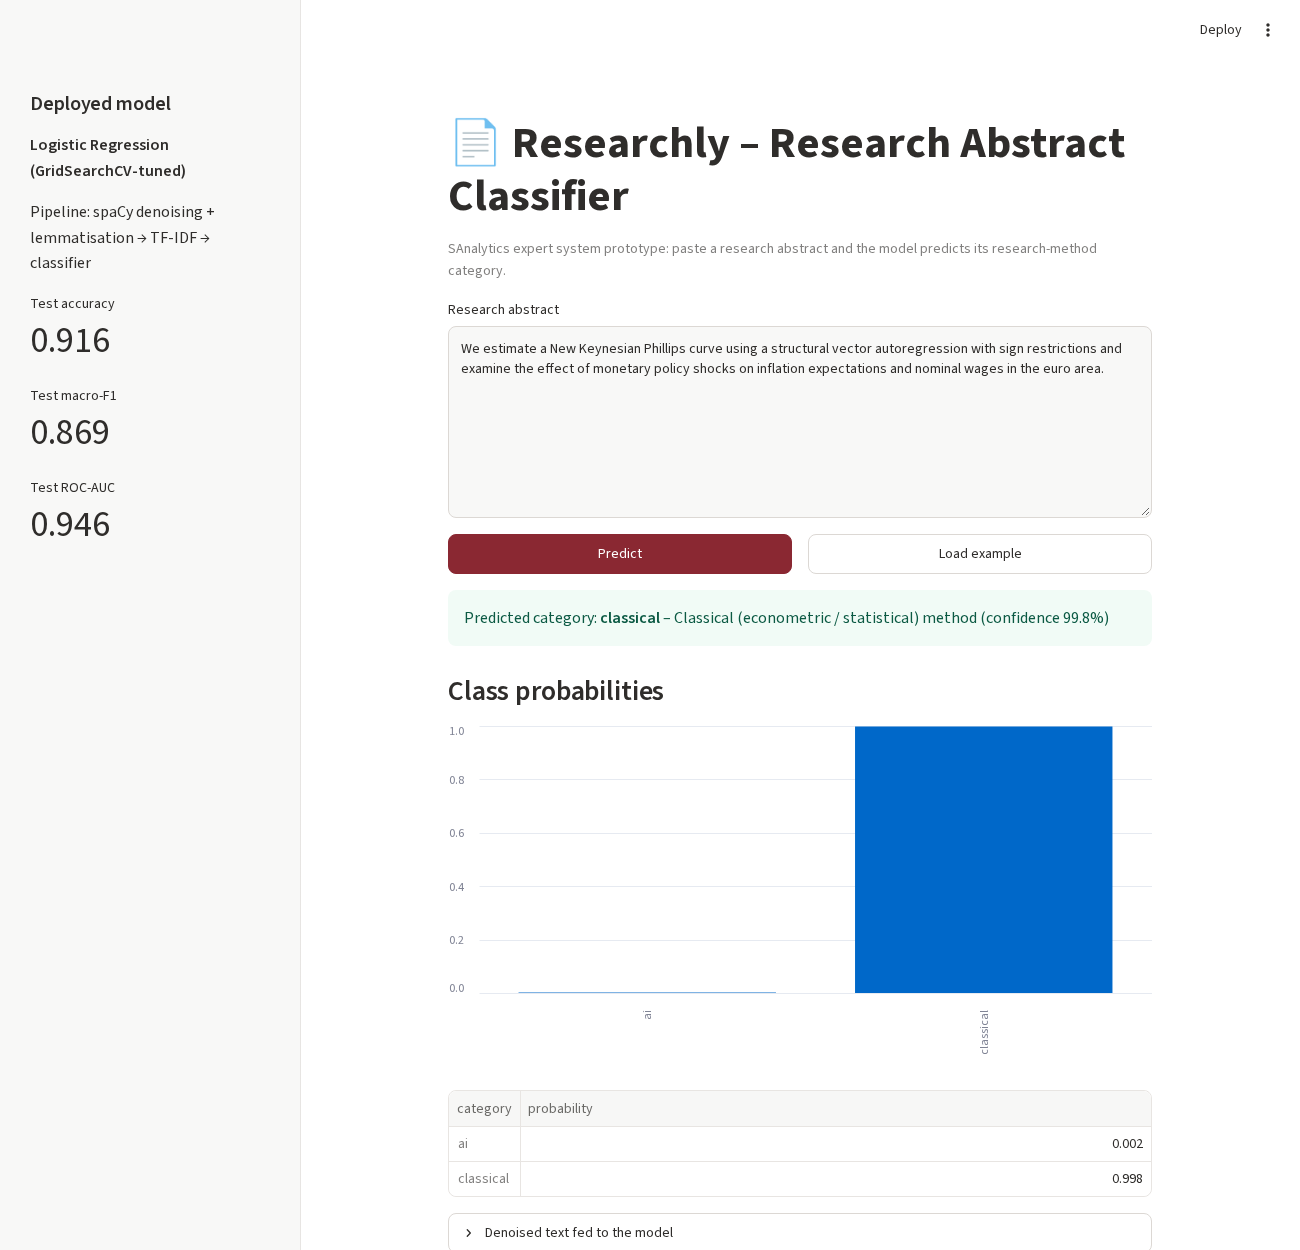

In [25]:
for f in ['q2_3_web_app_prediction_1.png', 'q2_3_web_app_prediction_2.png']:
    if os.path.exists(f'{FIG}/{f}'): display(Image(f'{FIG}/{f}', width=700))

In [26]:
json.dump(results, open(f'{RES}/part_a_results.json', 'w'), indent=2, default=str)
print('saved results')

saved results
